In [155]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import KBinsDiscretizer
warnings.filterwarnings('ignore')


In [ ]:
train = pd.read_csv("train_Insurance.csv", sep=";", decimal=",")
train.head()

,policy_id,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,risk_score,Geo_Code,claim
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,H13501,2012.0,1,1.0,N/V,V,U,1240.0,Wood-framed,without,NaN,75117,non
3,H14962,2012.0,1,0.0,N/V,V,U,900.0,Non-combustible,without,NaN,62916,non
4,H17755,2013.0,1,1.0,V/N,O,R,4984.0,Non-combustible,4,NaN,31149,oui


In [ ]:
test=pd.read_csv("test_Insurance.csv", sep=";", decimal=",")
test.head()

,policy_id,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,risk_score,Geo_Code,claim
0,H3733,2013,1,0,V/V,V,U,3760.0,Fire-resistive,without,"0,72",43157,oui
1,H16909,2015,1,0,V/N,O,R,1452.0,Fire-resistive,5,"0,45",58194,non
2,H16867,2013,1,1,V/N,O,R,1944.0,Ordinary,6,"0,79",92050,oui
3,H14813,2015,1,0,N/V,V,U,2270.0,Non-combustible,without,"0,66",13209,oui
4,H3728,2016,"0,5",0,V/N,O,R,2976.0,Fire-resistive,9,"0,18",5177,non


In [158]:
train.describe(include='all')

,policy_id,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,risk_score,Geo_Code,claim
count,5012,5012.000000,5012,5012.000000,5012,5008,5012,4935.000000,5012,5012,0.0,4939,5012
unique,5012,NaN,2,NaN,4,2,2,NaN,4,11,NaN,1115,2
top,H13501,NaN,1,NaN,V/N,O,R,NaN,Non-combustible,without,NaN,6088,non
freq,1,NaN,3706,NaN,2530,2532,2537,NaN,2310,2476,NaN,102,3886
mean,NaN,2013.660215,NaN,0.301077,NaN,NaN,NaN,1876.898683,NaN,NaN,NaN,NaN,NaN
std,NaN,1.383134,NaN,0.458772,NaN,NaN,NaN,2267.277397,NaN,NaN,NaN,NaN,NaN
min,NaN,2012.000000,NaN,0.000000,NaN,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN
25%,NaN,2012.000000,NaN,0.000000,NaN,NaN,NaN,520.000000,NaN,NaN,NaN,NaN,NaN
50%,NaN,2013.000000,NaN,0.000000,NaN,NaN,NaN,1067.000000,NaN,NaN,NaN,NaN,NaN
75%,NaN,2015.000000,NaN,1.000000,NaN,NaN,NaN,2280.000000,NaN,NaN,NaN,NaN,NaN


In [159]:
test.describe(include="all")

,policy_id,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,risk_score,Geo_Code,claim
count,2147,2147.000000,2147,2147.000000,2147,2144,2147,2118.000000,2147,2147,2147,2118,2147
unique,2147,NaN,2,NaN,4,2,2,NaN,4,11,81,714,2
top,H3733,NaN,1,NaN,V/N,V,U,NaN,Non-combustible,without,"0,78",6088,non
freq,1,NaN,1618,NaN,1071,1074,1074,NaN,995,1074,38,41,1639
mean,NaN,2013.691197,NaN,0.315789,NaN,NaN,NaN,1899.700189,NaN,NaN,NaN,NaN,NaN
std,NaN,1.385631,NaN,0.464938,NaN,NaN,NaN,2304.300053,NaN,NaN,NaN,NaN,NaN
min,NaN,2012.000000,NaN,0.000000,NaN,NaN,NaN,10.000000,NaN,NaN,NaN,NaN,NaN
25%,NaN,2012.000000,NaN,0.000000,NaN,NaN,NaN,535.500000,NaN,NaN,NaN,NaN,NaN
50%,NaN,2013.000000,NaN,0.000000,NaN,NaN,NaN,1100.000000,NaN,NaN,NaN,NaN,NaN
75%,NaN,2015.000000,NaN,1.000000,NaN,NaN,NaN,2300.000000,NaN,NaN,NaN,NaN,NaN


In [160]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5014 entries, 0 to 5013
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   policy_id               5012 non-null   object 
 1   year                    5012 non-null   float64
 2   coverage_period         5012 non-null   object 
 3   is_residential          5012 non-null   float64
 4   is_finished_and_fenced  5012 non-null   object 
 5   has_garden              5008 non-null   object 
 6   locality                5012 non-null   object 
 7   area_m2                 4935 non-null   float64
 8   structure_type          5012 non-null   object 
 9   window_count            5012 non-null   object 
 10  risk_score              0 non-null      float64
 11  Geo_Code                4939 non-null   object 
 12  claim                   5012 non-null   object 
dtypes: float64(4), object(9)
memory usage: 509.4+ KB


In [161]:
test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2147 entries, 0 to 2146
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   policy_id               2147 non-null   object 
 1   year                    2147 non-null   int64  
 2   coverage_period         2147 non-null   object 
 3   is_residential          2147 non-null   int64  
 4   is_finished_and_fenced  2147 non-null   object 
 5   has_garden              2144 non-null   object 
 6   locality                2147 non-null   object 
 7   area_m2                 2118 non-null   float64
 8   structure_type          2147 non-null   object 
 9   window_count            2147 non-null   object 
 10  risk_score              2147 non-null   object 
 11  Geo_Code                2118 non-null   object 
 12  claim                   2147 non-null   object 
dtypes: float64(1), int64(2), object(10)
memory usage: 218.2+ KB


In [162]:
train.isnull().sum()

policy_id                    2
year                         2
coverage_period              2
is_residential               2
is_finished_and_fenced       2
has_garden                   6
locality                     2
area_m2                     79
structure_type               2
window_count                 2
risk_score                5014
Geo_Code                    75
claim                        2
dtype: int64

In [163]:
test.isnull().sum()

policy_id                  0
year                       0
coverage_period            0
is_residential             0
is_finished_and_fenced     0
has_garden                 3
locality                   0
area_m2                   29
structure_type             0
window_count               0
risk_score                 0
Geo_Code                  29
claim                      0
dtype: int64

In [164]:
train.isnull().sum().sum()

np.int64(5192)

In [ ]:
test.isnull().sum().sum()

np.int64(61)

In [166]:
def impute_mode(df, col):
    imputer = SimpleImputer(strategy='most_frequent')
    df[[col]] = imputer.fit_transform(df[[col]])
    return df
def impute_median(df, col):
    imputer = SimpleImputer(strategy='median')
    df[[col]] = imputer.fit_transform(df[[col]])
    return df
def drop_nan(df, col):
    return df.dropna(subset=[col])

In [167]:
train["window_count"].replace("without",0, inplace=True)


In [168]:
test["window_count"].replace("without",0, inplace=True)


In [169]:
test['window_count'] = test['window_count'].replace('>=10', 10)


In [170]:
train['window_count'] = train['window_count'].replace('>=10', 10)


In [171]:
mode_cols = ['year', 'coverage_period', 'is_residential', 
             'is_finished_and_fenced', 'has_garden', 'locality', 
             'structure_type', 'Geo_Code']

for col in mode_cols:
    train = impute_mode(train, col)
    
median_cols = ['area_m2', 'window_count']
for col in median_cols:
    train = impute_median(train, col)
train = drop_nan(train, 'claim')


In [172]:
train.isnull().sum()

policy_id                    0
year                         0
coverage_period              0
is_residential               0
is_finished_and_fenced       0
has_garden                   0
locality                     0
area_m2                      0
structure_type               0
window_count                 0
risk_score                5012
Geo_Code                     0
claim                        0
dtype: int64

In [173]:
train.drop(columns=['risk_score'], inplace=True)

In [174]:
test.drop(columns=['risk_score'], inplace=True)

In [175]:
mode_cols_test = [ 'has_garden','Geo_Code']

for col in mode_cols_test:
    test = impute_mode(test, col)
    
median_cols_test = ['area_m2']
for col in median_cols_test:
    test = impute_median(test, col)


In [176]:
test.isnull().sum()

policy_id                 0
year                      0
coverage_period           0
is_residential            0
is_finished_and_fenced    0
has_garden                0
locality                  0
area_m2                   0
structure_type            0
window_count              0
Geo_Code                  0
claim                     0
dtype: int64

In [177]:

train['Geo_Code'] = pd.to_numeric(train['Geo_Code'], errors='coerce')
train.dropna(subset=["Geo_Code"],axis=0, inplace=True)
train['Geo_Code'].astype("int64")
enc = KBinsDiscretizer(n_bins=10, encode='ordinal', strategy='quantile', subsample=len(train)) #Geo code ranges from 1000 to 100 000
train['Geo_Code'] = enc.fit_transform(train[['Geo_Code']])
train

,policy_id,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim
2,H13501,2012.0,1,1.0,N/V,V,U,1240.0,Wood-framed,0.0,7.0,non
3,H14962,2012.0,1,0.0,N/V,V,U,900.0,Non-combustible,0.0,5.0,non
4,H17755,2013.0,1,1.0,V/N,O,R,4984.0,Non-combustible,4.0,3.0,oui
5,H13369,2016.0,"0,5",0.0,N/V,V,U,600.0,Wood-framed,0.0,0.0,oui
6,H12988,2012.0,1,0.0,N/V,V,U,900.0,Non-combustible,0.0,5.0,non
...,...,...,...,...,...,...,...,...,...,...,...,...
5009,H13682,2013.0,1,0.0,N/V,V,U,550.0,Ordinary,0.0,3.0,oui
5010,H18342,2012.0,"0,5",0.0,V/N,O,R,1000.0,Fire-resistive,4.0,1.0,non
5011,H16892,2015.0,1,1.0,V/N,O,R,480.0,Ordinary,3.0,9.0,non
5012,H18805,2012.0,"0,5",0.0,V/N,O,R,536.0,Fire-resistive,4.0,7.0,non


In [178]:
test['Geo_Code'] = pd.to_numeric(test['Geo_Code'], errors='coerce')
test.dropna(subset=["Geo_Code"],axis=0, inplace=True)
test['Geo_Code'].astype("int64")
enc = KBinsDiscretizer(n_bins=10, encode='ordinal',strategy='quantile', subsample=len(test))
test['Geo_Code'] = enc.fit_transform(test[['Geo_Code']])
test

,policy_id,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim
0,H3733,2013,1,0,V/V,V,U,3760.0,Fire-resistive,0,4.0,oui
1,H16909,2015,1,0,V/N,O,R,1452.0,Fire-resistive,5,5.0,non
2,H16867,2013,1,1,V/N,O,R,1944.0,Ordinary,6,9.0,oui
3,H14813,2015,1,0,N/V,V,U,2270.0,Non-combustible,0,2.0,oui
4,H3728,2016,"0,5",0,V/N,O,R,2976.0,Fire-resistive,9,0.0,non
...,...,...,...,...,...,...,...,...,...,...,...,...
2142,H19924,2016,"0,5",1,V/N,O,R,862.0,Wood-framed,2,0.0,non
2143,H17249,2012,1,0,V/V,V,U,1100.0,Non-combustible,0,0.0,non
2144,H18804,2014,1,0,V/N,O,R,730.0,Non-combustible,3,6.0,non
2145,H12650,2014,1,1,N/V,V,U,568.0,Non-combustible,0,6.0,oui


In [179]:
l_num=list(train.select_dtypes(include="number"))
print(l_num)

['year', 'is_residential', 'area_m2', 'window_count', 'Geo_Code']


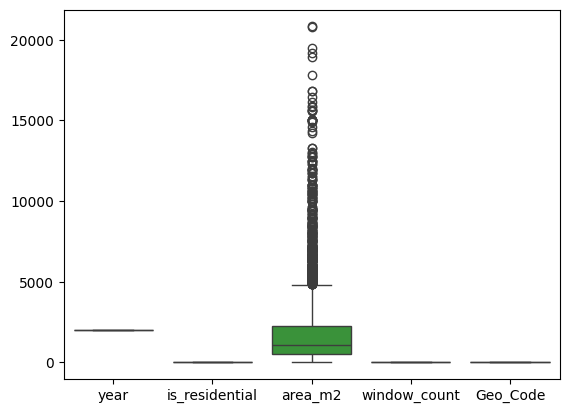

In [180]:
sns.boxplot(data=train[l_num])
plt.show()

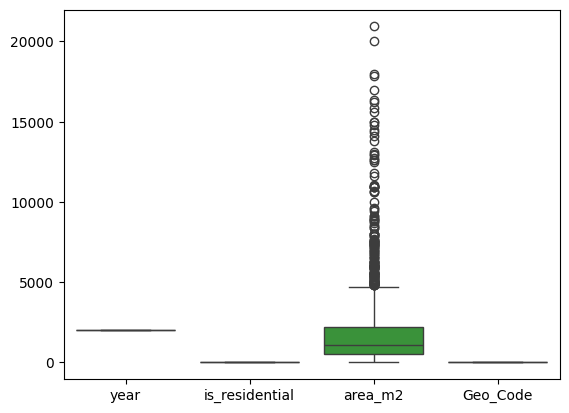

In [181]:
sns.boxplot(data=test[l_num])
plt.show()

In [182]:
train.describe(include='all')

,policy_id,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim
count,4974,4974.000000,4974,4974.000000,4974,4974,4974,4974.000000,4974,4974.000000,4974.000000,4974
unique,4974,NaN,2,NaN,4,2,2,NaN,4,NaN,NaN,2
top,H13501,NaN,1,NaN,V/N,O,R,NaN,Non-combustible,NaN,NaN,non
freq,1,NaN,3676,NaN,2497,2503,2504,NaN,2310,NaN,NaN,3858
mean,NaN,2013.659630,NaN,0.303378,NaN,NaN,NaN,1857.265983,NaN,2.189988,4.515480,NaN
std,NaN,1.384232,NaN,0.459763,NaN,NaN,NaN,2252.842316,NaN,2.529276,2.868255,NaN
min,NaN,2012.000000,NaN,0.000000,NaN,NaN,NaN,1.000000,NaN,0.000000,0.000000,NaN
25%,NaN,2012.000000,NaN,0.000000,NaN,NaN,NaN,530.000000,NaN,0.000000,2.000000,NaN
50%,NaN,2013.000000,NaN,0.000000,NaN,NaN,NaN,1067.000000,NaN,1.000000,5.000000,NaN
75%,NaN,2015.000000,NaN,1.000000,NaN,NaN,NaN,2247.750000,NaN,4.000000,7.000000,NaN


In [183]:
def boxplot_treatment(df):
  Q1,Q3=np.percentile(df["area_m2"],[25,75])
  IQR=Q3-Q1
  lower_limit=max(Q1 - 1.5 * IQR, df["area_m2"].min()+100) 
  upper_limit=Q3+1.5*IQR
  df['area_m2']=np.where(df['area_m2']>=upper_limit,
  upper_limit,df['area_m2'])
  return df
train=boxplot_treatment(train)
test=boxplot_treatment(test)

In [184]:
train.describe(include='all')

,policy_id,year,coverage_period,is_residential,is_finished_and_fenced,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim
count,4974,4974.000000,4974,4974.000000,4974,4974,4974,4974.000000,4974,4974.000000,4974.000000,4974
unique,4974,NaN,2,NaN,4,2,2,NaN,4,NaN,NaN,2
top,H13501,NaN,1,NaN,V/N,O,R,NaN,Non-combustible,NaN,NaN,non
freq,1,NaN,3676,NaN,2497,2503,2504,NaN,2310,NaN,NaN,3858
mean,NaN,2013.659630,NaN,0.303378,NaN,NaN,NaN,1610.941848,NaN,2.189988,4.515480,NaN
std,NaN,1.384232,NaN,0.459763,NaN,NaN,NaN,1412.594381,NaN,2.529276,2.868255,NaN
min,NaN,2012.000000,NaN,0.000000,NaN,NaN,NaN,1.000000,NaN,0.000000,0.000000,NaN
25%,NaN,2012.000000,NaN,0.000000,NaN,NaN,NaN,530.000000,NaN,0.000000,2.000000,NaN
50%,NaN,2013.000000,NaN,0.000000,NaN,NaN,NaN,1067.000000,NaN,1.000000,5.000000,NaN
75%,NaN,2015.000000,NaN,1.000000,NaN,NaN,NaN,2247.750000,NaN,4.000000,7.000000,NaN


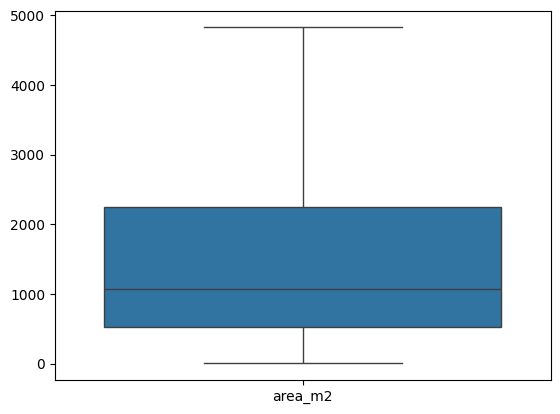

In [185]:
sns.boxplot(data=train[['area_m2']])
plt.show()

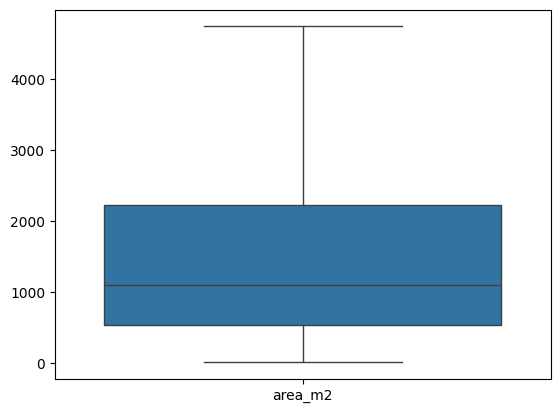

In [186]:
sns.boxplot(data=test[['area_m2']])
plt.show()

In [187]:
train[['is_finished', 'is_fenced']] = train['is_finished_and_fenced'].str.split('/', expand=True)
train =train.drop('is_finished_and_fenced', axis=1)
train['is_finished'] = train['is_finished'].map({'N':0, 'V':1})
train['is_fenced']   = train['is_fenced'].map({'N':0, 'V':1})
train.head()

,policy_id,year,coverage_period,is_residential,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim,is_finished,is_fenced
2,H13501,2012.0,1,1.0,V,U,1240.000,Wood-framed,0.0,7.0,non,0,1
3,H14962,2012.0,1,0.0,V,U,900.000,Non-combustible,0.0,5.0,non,0,1
4,H17755,2013.0,1,1.0,O,R,4824.375,Non-combustible,4.0,3.0,oui,1,0
5,H13369,2016.0,"0,5",0.0,V,U,600.000,Wood-framed,0.0,0.0,oui,0,1
6,H12988,2012.0,1,0.0,V,U,900.000,Non-combustible,0.0,5.0,non,0,1


In [188]:
test[['is_finished', 'is_fenced']] = test['is_finished_and_fenced'].str.split('/', expand=True)
test = test.drop('is_finished_and_fenced', axis=1)
test['is_finished'] = test['is_finished'].map({'N':0, 'V':1})
test['is_fenced']   = test['is_fenced'].map({'N':0, 'V':1})
test.head()


,policy_id,year,coverage_period,is_residential,has_garden,locality,area_m2,structure_type,window_count,Geo_Code,claim,is_finished,is_fenced
0,H3733,2013,1,0,V,U,3760.0,Fire-resistive,0,4.0,oui,1,1
1,H16909,2015,1,0,O,R,1452.0,Fire-resistive,5,5.0,non,1,0
2,H16867,2013,1,1,O,R,1944.0,Ordinary,6,9.0,oui,1,0
3,H14813,2015,1,0,V,U,2270.0,Non-combustible,0,2.0,oui,0,1
4,H3728,2016,"0,5",0,O,R,2976.0,Fire-resistive,9,0.0,non,1,0


In [189]:
enc = OrdinalEncoder()
train[["is_residential"]]=enc.fit_transform(
train.loc[:,["is_residential"]])


enc = OrdinalEncoder()
train[["claim"]]=enc.fit_transform(
train.loc[:,["claim"]])

enc = OrdinalEncoder()
train[["locality"]]=enc.fit_transform(
train.loc[:,["locality"]])

enc = OrdinalEncoder()
train[["has_garden"]]=enc.fit_transform(
train.loc[:,["has_garden"]])

train = pd.get_dummies(train, columns=['structure_type'], dtype='int32', prefix='', prefix_sep='')
claim_column = train.pop('claim')
train = pd.concat([train, claim_column], axis=1)

train =train.drop('policy_id', axis=1)
train

,year,coverage_period,is_residential,has_garden,locality,area_m2,window_count,Geo_Code,is_finished,is_fenced,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim
2,2012.0,1,1.0,1.0,1.0,1240.000,0.0,7.0,0,1,0,0,0,1,0.0
3,2012.0,1,0.0,1.0,1.0,900.000,0.0,5.0,0,1,0,1,0,0,0.0
4,2013.0,1,1.0,0.0,0.0,4824.375,4.0,3.0,1,0,0,1,0,0,1.0
5,2016.0,"0,5",0.0,1.0,1.0,600.000,0.0,0.0,0,1,0,0,0,1,1.0
6,2012.0,1,0.0,1.0,1.0,900.000,0.0,5.0,0,1,0,1,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5009,2013.0,1,0.0,1.0,1.0,550.000,0.0,3.0,0,1,0,0,1,0,1.0
5010,2012.0,"0,5",0.0,0.0,0.0,1000.000,4.0,1.0,1,0,1,0,0,0,0.0
5011,2015.0,1,1.0,0.0,0.0,480.000,3.0,9.0,1,0,0,0,1,0,0.0
5012,2012.0,"0,5",0.0,0.0,0.0,536.000,4.0,7.0,1,0,1,0,0,0,0.0


In [190]:
enc = OrdinalEncoder()
test[["is_residential"]] = enc.fit_transform(
    test.loc[:, ["is_residential"]]
)

enc = OrdinalEncoder()
test[["claim"]] = enc.fit_transform(
    test.loc[:, ["claim"]]
)

enc = OrdinalEncoder()
test[["locality"]] = enc.fit_transform(
    test.loc[:, ["locality"]]
)

enc = OrdinalEncoder()
test[["has_garden"]]=enc.fit_transform(
test.loc[:,["has_garden"]])


test = pd.get_dummies(test, columns=['structure_type'], dtype='int32', prefix='', prefix_sep='')

claim_column = test.pop('claim')
test = pd.concat([test, claim_column], axis=1)

test = test.drop('policy_id', axis=1)
test

,year,coverage_period,is_residential,has_garden,locality,area_m2,window_count,Geo_Code,is_finished,is_fenced,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim
0,2013,1,0.0,1.0,1.0,3760.0,0,4.0,1,1,1,0,0,0,1.0
1,2015,1,0.0,0.0,0.0,1452.0,5,5.0,1,0,1,0,0,0,0.0
2,2013,1,1.0,0.0,0.0,1944.0,6,9.0,1,0,0,0,1,0,1.0
3,2015,1,0.0,1.0,1.0,2270.0,0,2.0,0,1,0,1,0,0,1.0
4,2016,"0,5",0.0,0.0,0.0,2976.0,9,0.0,1,0,1,0,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2142,2016,"0,5",1.0,0.0,0.0,862.0,2,0.0,1,0,0,0,0,1,0.0
2143,2012,1,0.0,1.0,1.0,1100.0,0,0.0,1,1,0,1,0,0,0.0
2144,2014,1,0.0,0.0,0.0,730.0,3,6.0,1,0,0,1,0,0,0.0
2145,2014,1,1.0,1.0,1.0,568.0,0,6.0,0,1,0,1,0,0,1.0


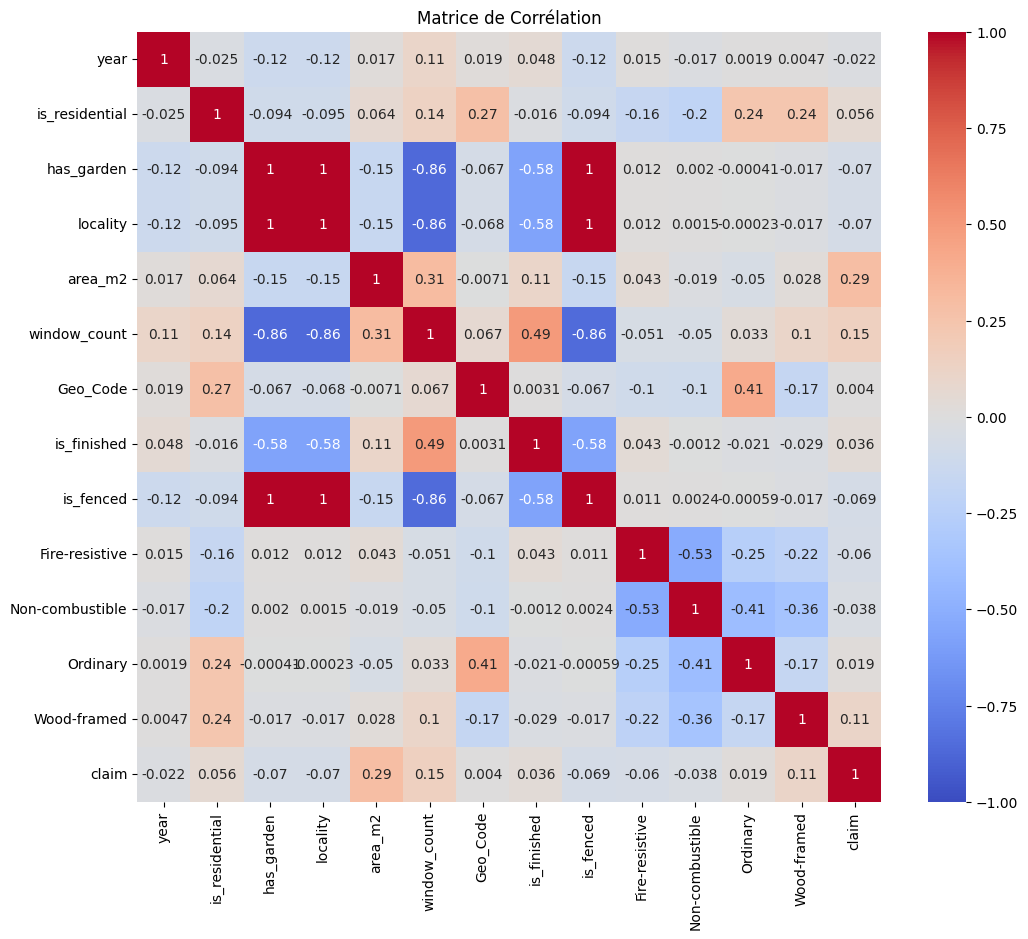

In [191]:
df_train = train.corr(numeric_only=True)
plt.figure(figsize=(12, 10))
sns.heatmap(df_train, annot=True, vmin=-1, vmax=1, cmap="coolwarm")
plt.title('Matrice de Corrélation')
plt.show()

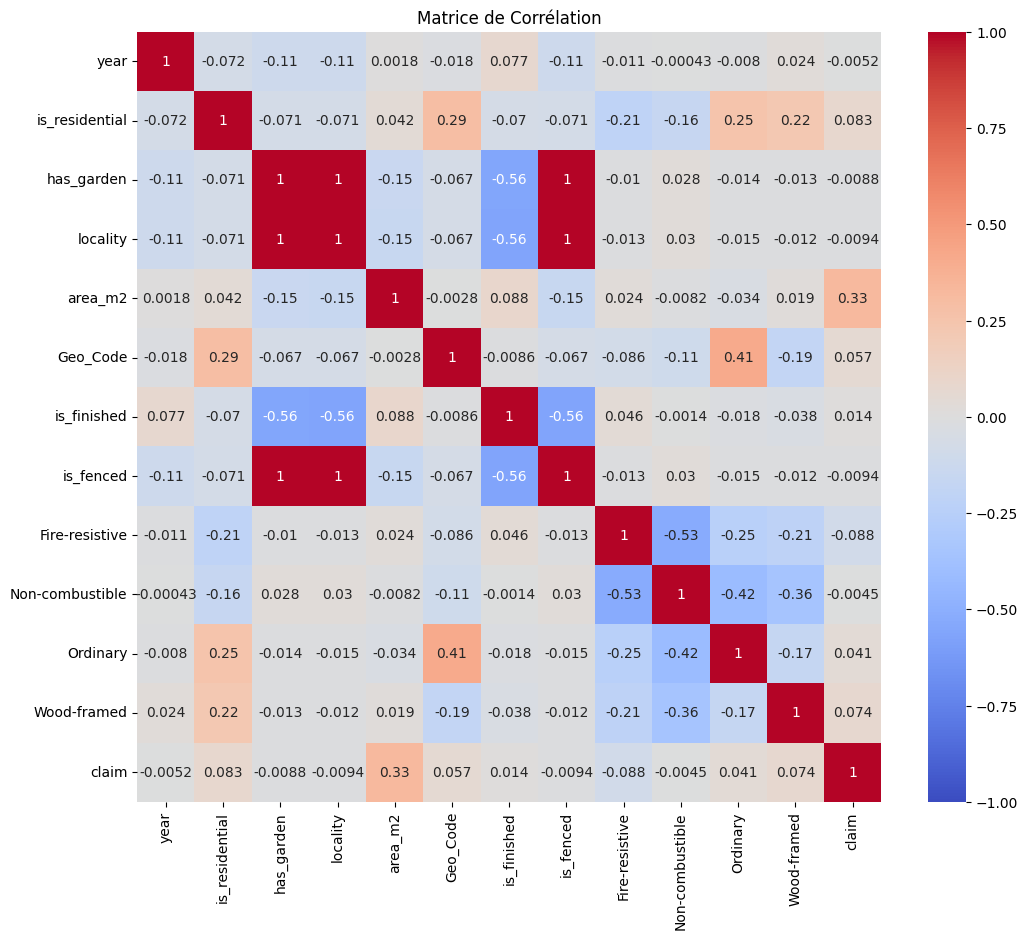

In [192]:
df_test = test.corr(numeric_only=True)
plt.figure(figsize=(12, 10))
sns.heatmap(df_test, annot=True, vmin=-1, vmax=1, cmap="coolwarm")
plt.title('Matrice de Corrélation')
plt.show()


X = train.drop('claim', axis=1)
y = train['claim']


categorical_cols = X.select_dtypes(include=['object']).columns


X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)


if y.dtype == 'object':
    le = LabelEncoder()
    y = le.fit_transform(y)


X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf = RandomForestClassifier()
rf.fit(X_train, y_train)


importances = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Affichage complet
print(importances)


plt.figure(figsize=(12, 8))
sns.barplot(x="Importance", y="Feature", data=importances.head(20), palette="viridis")
plt.title("Top 20 Feature Importances (RandomForest)")
plt.show()


accuracy = rf.score(X_test, y_test)
print(f"Accuracy sur le test set : {accuracy:.4f}")


In [193]:

train =train.drop('year', axis=1) #year of observation is not important but an historical data
train =train.drop('is_finished', axis=1)
train =train.drop('is_fenced', axis=1)
train =train.drop('has_garden', axis=1)
train =train.drop('locality', axis=1)
train

,coverage_period,is_residential,area_m2,window_count,Geo_Code,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim
2,1,1.0,1240.000,0.0,7.0,0,0,0,1,0.0
3,1,0.0,900.000,0.0,5.0,0,1,0,0,0.0
4,1,1.0,4824.375,4.0,3.0,0,1,0,0,1.0
5,"0,5",0.0,600.000,0.0,0.0,0,0,0,1,1.0
6,1,0.0,900.000,0.0,5.0,0,1,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...
5009,1,0.0,550.000,0.0,3.0,0,0,1,0,1.0
5010,"0,5",0.0,1000.000,4.0,1.0,1,0,0,0,0.0
5011,1,1.0,480.000,3.0,9.0,0,0,1,0,0.0
5012,"0,5",0.0,536.000,4.0,7.0,1,0,0,0,0.0


In [194]:
test = test.drop('year', axis=1)          
test = test.drop('is_finished', axis=1)
test = test.drop('is_fenced', axis=1)
test = test.drop('has_garden', axis=1)
test = test.drop('locality', axis=1)
test

,coverage_period,is_residential,area_m2,window_count,Geo_Code,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim
0,1,0.0,3760.0,0,4.0,1,0,0,0,1.0
1,1,0.0,1452.0,5,5.0,1,0,0,0,0.0
2,1,1.0,1944.0,6,9.0,0,0,1,0,1.0
3,1,0.0,2270.0,0,2.0,0,1,0,0,1.0
4,"0,5",0.0,2976.0,9,0.0,1,0,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...
2142,"0,5",1.0,862.0,2,0.0,0,0,0,1,0.0
2143,1,0.0,1100.0,0,0.0,0,1,0,0,0.0
2144,1,0.0,730.0,3,6.0,0,1,0,0,0.0
2145,1,1.0,568.0,0,6.0,0,1,0,0,1.0


In [195]:
train1=train[train.duplicated()]
train1

,coverage_period,is_residential,area_m2,window_count,Geo_Code,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim
6,1,0.0,900.000,0.0,5.0,0,1,0,0,0.0
27,1,0.0,900.000,0.0,5.0,0,1,0,0,0.0
69,1,0.0,900.000,0.0,5.0,0,1,0,0,0.0
161,"0,5",0.0,4824.375,5.0,5.0,0,1,0,0,1.0
170,1,0.0,4824.375,0.0,6.0,0,1,0,0,1.0
...,...,...,...,...,...,...,...,...,...,...
4984,"0,5",0.0,4824.375,0.0,2.0,0,1,0,0,0.0
4996,1,0.0,4142.000,10.0,4.0,0,1,0,0,0.0
5005,1,1.0,1176.000,0.0,9.0,0,0,1,0,1.0
5007,"0,5",0.0,300.000,0.0,2.0,0,1,0,0,0.0


In [196]:
train.drop_duplicates(inplace=True, ignore_index=True)
train

,coverage_period,is_residential,area_m2,window_count,Geo_Code,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim
0,1,1.0,1240.000,0.0,7.0,0,0,0,1,0.0
1,1,0.0,900.000,0.0,5.0,0,1,0,0,0.0
2,1,1.0,4824.375,4.0,3.0,0,1,0,0,1.0
3,"0,5",0.0,600.000,0.0,0.0,0,0,0,1,1.0
4,"0,5",0.0,2675.000,0.0,4.0,0,0,1,0,0.0
...,...,...,...,...,...,...,...,...,...,...
4293,"0,5",0.0,173.000,0.0,2.0,0,1,0,0,0.0
4294,1,0.0,550.000,0.0,3.0,0,0,1,0,1.0
4295,"0,5",0.0,1000.000,4.0,1.0,1,0,0,0,0.0
4296,"0,5",0.0,536.000,4.0,7.0,1,0,0,0,0.0


In [197]:
train1=train[train.duplicated()]
train1

,coverage_period,is_residential,area_m2,window_count,Geo_Code,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim


In [198]:
test1=test[test.duplicated()]
test1

,coverage_period,is_residential,area_m2,window_count,Geo_Code,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim
136,1,0.0,4740.0,4,7.0,0,1,0,0,1.0
413,1,1.0,520.0,0,3.0,1,0,0,0,0.0
431,1,0.0,1100.0,0,0.0,1,0,0,0,0.0
435,1,1.0,850.0,4,9.0,0,0,1,0,0.0
439,1,0.0,1100.0,0,0.0,0,1,0,0,1.0
...,...,...,...,...,...,...,...,...,...,...
2116,1,0.0,1500.0,0,6.0,0,1,0,0,0.0
2122,1,0.0,460.0,0,4.0,0,1,0,0,0.0
2125,1,0.0,1325.0,0,4.0,0,0,1,0,0.0
2135,1,0.0,600.0,0,1.0,0,1,0,0,0.0


In [199]:
test.drop_duplicates(inplace=True, ignore_index=True)
test

,coverage_period,is_residential,area_m2,window_count,Geo_Code,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim
0,1,0.0,3760.0,0,4.0,1,0,0,0,1.0
1,1,0.0,1452.0,5,5.0,1,0,0,0,0.0
2,1,1.0,1944.0,6,9.0,0,0,1,0,1.0
3,1,0.0,2270.0,0,2.0,0,1,0,0,1.0
4,"0,5",0.0,2976.0,9,0.0,1,0,0,0,0.0
...,...,...,...,...,...,...,...,...,...,...
1975,"0,5",0.0,400.0,4,2.0,1,0,0,0,0.0
1976,"0,5",1.0,862.0,2,0.0,0,0,0,1,0.0
1977,1,0.0,730.0,3,6.0,0,1,0,0,0.0
1978,1,1.0,568.0,0,6.0,0,1,0,0,1.0


In [200]:
test1=test[test.duplicated()]
test1

,coverage_period,is_residential,area_m2,window_count,Geo_Code,Fire-resistive,Non-combustible,Ordinary,Wood-framed,claim


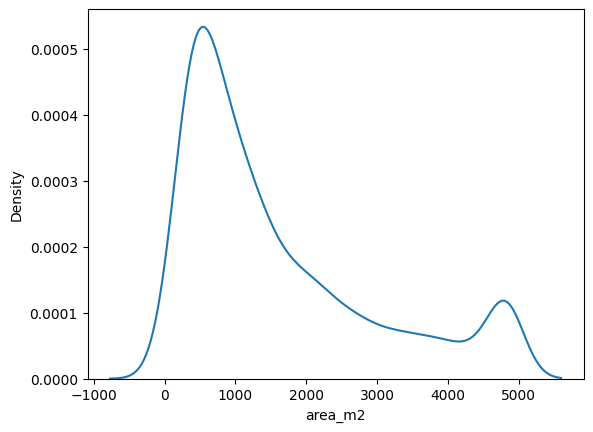

In [201]:
sns.kdeplot(train['area_m2'],bw_method='scott',bw_adjust=1)
plt.show()

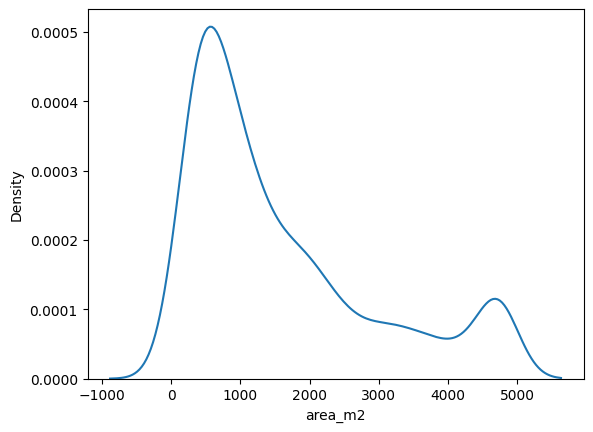

In [202]:
sns.kdeplot(test['area_m2'],bw_method='scott',bw_adjust=1)
plt.show()

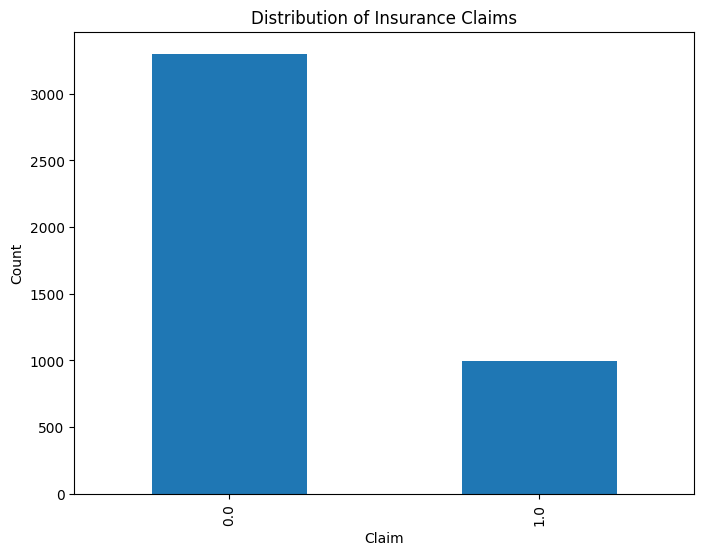

In [203]:
plt.figure(figsize=(8, 6))
train['claim'].value_counts().plot(kind='bar')
plt.title('Distribution of Insurance Claims')
plt.xlabel('Claim')
plt.ylabel('Count')
plt.show()

In [204]:
train['coverage_period'] = train['coverage_period'].astype(str).str.replace(',', '.').astype('float64')
test['coverage_period'] = test['coverage_period'].astype(str).str.replace(',', '.').astype('float64')

Après rééquilibrage : claim
0.0    3047
1.0    3047
Name: count, dtype: int64


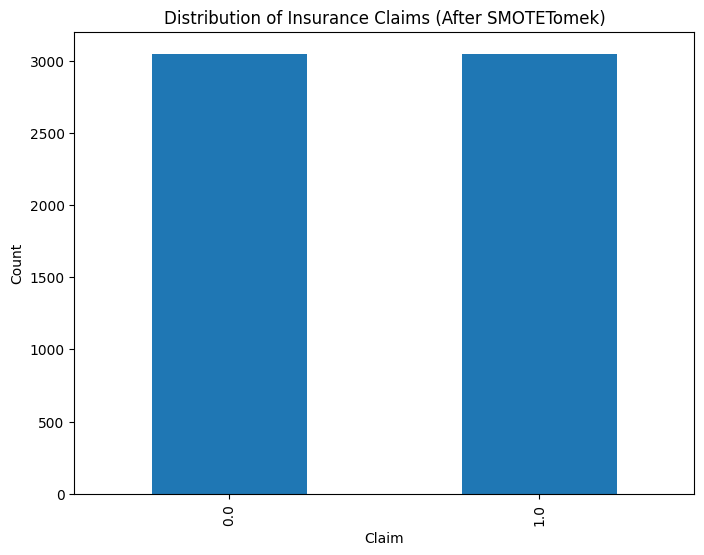

X_train shape: (4884, 9)
X_val shape: (860, 9)
Distribution Y_train:
 claim
0.0    2442
1.0    2442
Name: count, dtype: int64
Distribution Y_val:
 claim
0.0    661
1.0    199
Name: count, dtype: int64


In [205]:
from imblearn.combine import SMOTETomek
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# 1️⃣ Séparation X et Y
# -----------------------------
X = train.drop('claim', axis=1)
y = train['claim']

# -----------------------------
# 2️⃣ Appliquer SMOTE + Tomek Links
# -----------------------------
smote_tomek = SMOTETomek(random_state=42)
X_resampled, y_resampled = smote_tomek.fit_resample(X, y)

# -----------------------------
# 3️⃣ Vérifier la distribution après rééquilibrage
# -----------------------------
print("Après rééquilibrage :", pd.Series(y_resampled).value_counts())

plt.figure(figsize=(8, 6))
pd.Series(y_resampled).value_counts().plot(kind='bar')
plt.title('Distribution of Insurance Claims (After SMOTETomek)')
plt.xlabel('Claim')
plt.ylabel('Count')
plt.show()

# -----------------------------
# 4️⃣ Standardisation
# -----------------------------
scaler = StandardScaler()
X_rescaled = scaler.fit_transform(X_resampled)

# -----------------------------
# 5️⃣ Split train/test (optionnel si tu as déjà test set)
# -----------------------------
X_train, X_val, Y_train, Y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

X_train, Y_train = smote_tomek.fit_resample(X_train, Y_train)


print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("Distribution Y_train:\n", pd.Series(Y_train).value_counts())
print("Distribution Y_val:\n", pd.Series(Y_val).value_counts())


In [206]:
train['window_count'] = pd.to_numeric(train['window_count']).astype('float64')
test['window_count']  = pd.to_numeric(test['window_count']).astype('float64')


from sklearn.model_selection import train_test_split

X = train.drop(columns=["Claim"])
y = train["Claim"]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)





KeyError: "['Claim'] not found in axis"

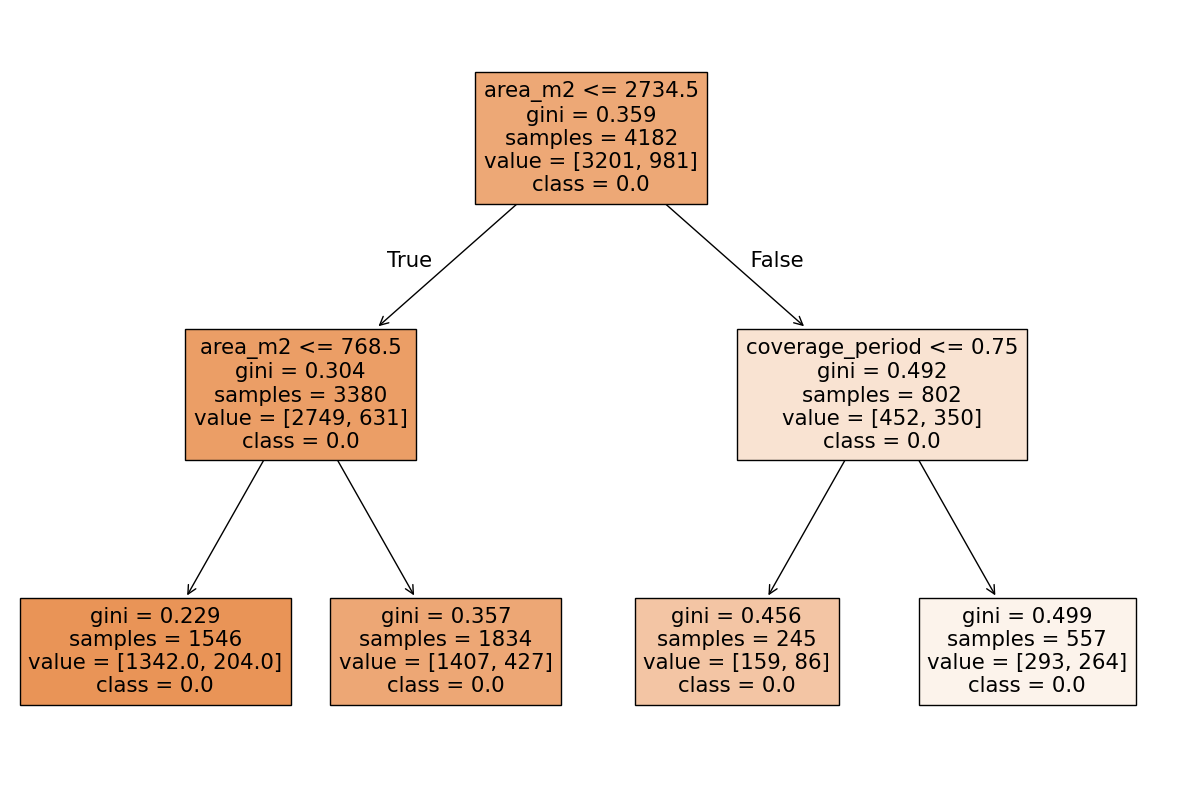

|--- area_m2 <= 2734.50
|   |--- area_m2 <= 768.50
|   |   |--- class: 0.0
|   |--- area_m2 >  768.50
|   |   |--- class: 0.0
|--- area_m2 >  2734.50
|   |--- coverage_period <= 0.75
|   |   |--- class: 0.0
|   |--- coverage_period >  0.75
|   |   |--- class: 0.0



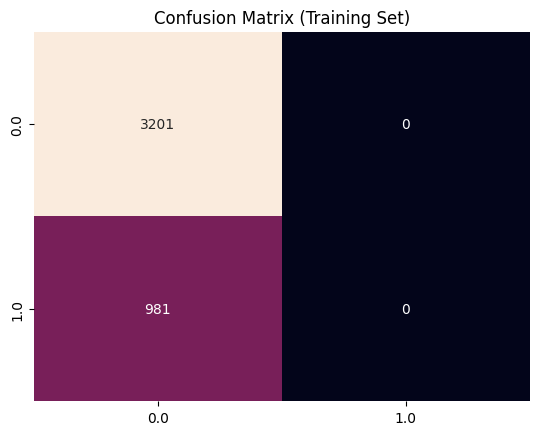

Accuracy on the training set: 76.54%


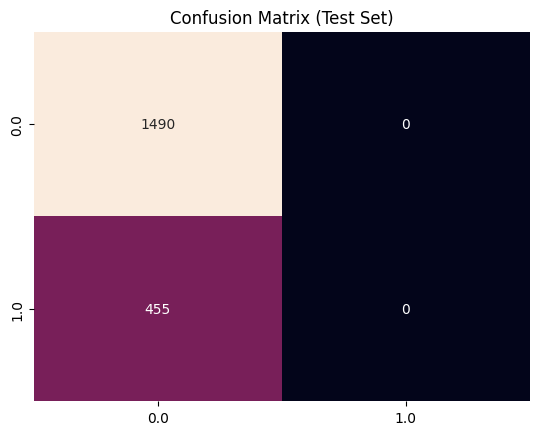

Accuracy on the test set: 76.61%
Training and testing completed.


In [ ]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming X_train, Y_train, X_test, Y_test, and train are defined

# Train the decision tree classifier
cls = DecisionTreeClassifier(max_depth=2)
cls.fit(X_train, Y_train)

# Visualize the decision tree
fig = plt.figure(figsize=(15, 10))
plot_tree(cls, feature_names=list(train)[:-1], class_names=[str(cls_class) for cls_class in cls.classes_], filled=True)
plt.show()

# Export text representation of the decision tree
print(export_text(cls, feature_names=list(train)[:-1]))

# Make predictions on the training set
Y_p_train = cls.predict(X_train)
c_m_train = confusion_matrix(Y_train, Y_p_train)

# Calculate accuracy for the training set
accuracy_train = accuracy_score(Y_train, Y_p_train)

# Visualize the confusion matrix for the training set
sns.heatmap(c_m_train, annot=True, cbar=False, xticklabels=[str(cls_class) for cls_class in cls.classes_], yticklabels=[str(cls_class) for cls_class in cls.classes_], fmt='d')
plt.title('Confusion Matrix (Training Set)')
plt.show()

print(f"Accuracy on the training set: {accuracy_train:.2%}")

# Make predictions on the test set
Y_p_test = cls.predict(X_test)
c_m_test = confusion_matrix(Y_test, Y_p_test)

# Calculate accuracy for the test set
accuracy_test = accuracy_score(Y_test, Y_p_test)

# Visualize the confusion matrix for the test set
sns.heatmap(c_m_test, annot=True, cbar=False, xticklabels=[str(cls_class) for cls_class in cls.classes_], yticklabels=[str(cls_class) for cls_class in cls.classes_], fmt='d')
plt.title('Confusion Matrix (Test Set)')
plt.show()

print(f"Accuracy on the test set: {accuracy_test:.2%}")
print("Training and testing completed.")


[0.76542324 0.        ] [1. 0.] [0.86712718 0.        ] [3201  981]


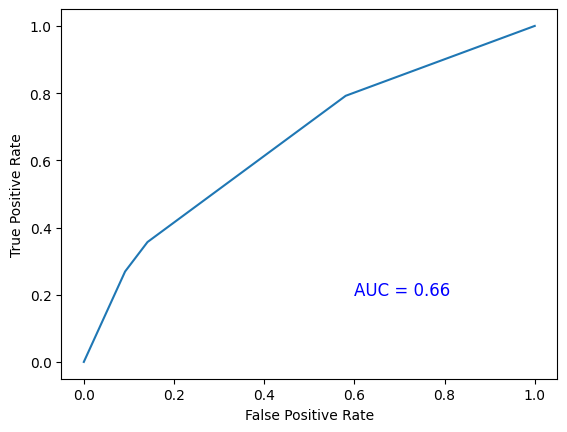

[0.76606684 0.        ] [1. 0.] [0.86754003 0.        ] [1490  455]


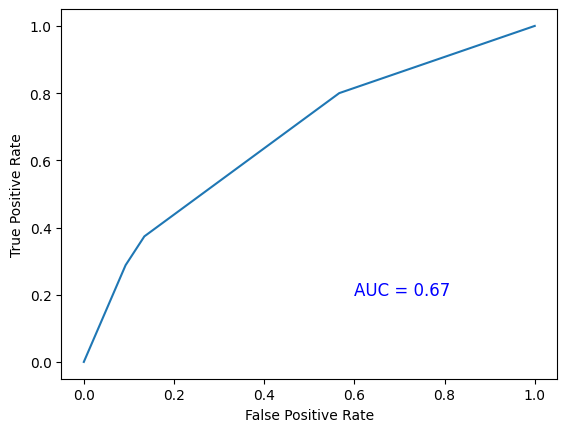

In [ ]:
from sklearn.metrics import precision_recall_fscore_support, roc_curve, roc_auc_score
precision,recall,f1,occ= precision_recall_fscore_support(Y_train,
Y_p_train, average=None)
print(precision, recall, f1, occ)
y_train_prob=cls.predict_proba(X_train)[:,1]
fpr,tpr,thresholds = roc_curve(Y_train,y_train_prob,pos_label=1)
auc = roc_auc_score(Y_train, y_train_prob)
plt.plot(fpr, tpr)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.text(0.6, 0.2, f'AUC = {auc:.2f}',
 color='blue',fontsize=12)
plt.show()
precision,recall,f1,occ= precision_recall_fscore_support(Y_test,
Y_p_test, average=None)
print(precision, recall, f1, occ)
y_test_prob=cls.predict_proba(X_test)[:,1]
fpr,tpr,thresholds = roc_curve(Y_test,y_test_prob,pos_label=1)
auc = roc_auc_score(Y_test, y_test_prob)
plt.plot(fpr, tpr)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.text(0.6, 0.2, f'AUC = {auc:.2f}',
 color='blue',fontsize=12)
plt.show()

In [ ]:
complement_recall = 1 - recall
print("Class-wise complement of recall:")
for i, class_label in enumerate(cls.classes_):
    print(f"Class {class_label}: {complement_recall[i]:.2%}")
complement_precision = 1 - precision
print("Class-wise complement of precision:")
for i, class_label in enumerate(cls.classes_):
    print(f"Class {class_label}: {complement_precision[i]:.2%}")

Class-wise complement of recall:
Class 0.0: 0.00%
Class 1.0: 100.00%
Class-wise complement of precision:
Class 0.0: 23.39%
Class 1.0: 100.00%


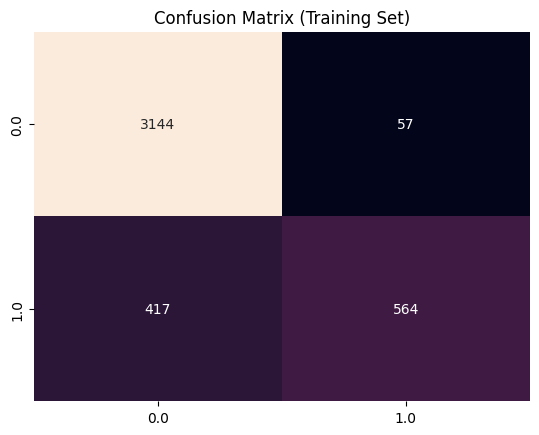

Accuracy on the training set: 88.67%


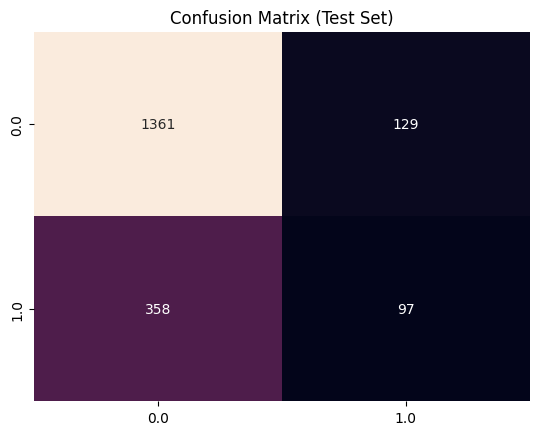

Accuracy on the test set: 74.96%
Training and testing completed.


In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming X_train, Y_train, X_test, Y_test, and train are defined

# Train the RandomForestClassifier
cls = RandomForestClassifier(
    n_estimators=100,
    criterion='gini',

    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    max_leaf_nodes=None,
    bootstrap=True,
    oob_score=True,
    max_samples=0.53
)
cls.fit(X_train, Y_train)

# Make predictions on the training set
Y_p_train = cls.predict(X_train)
c_m_train = confusion_matrix(Y_train, Y_p_train)

# Calculate accuracy for the training set
accuracy_train = accuracy_score(Y_train, Y_p_train)

# Visualize the confusion matrix for the training set
sns.heatmap(c_m_train, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Training Set)')
plt.show()

print(f"Accuracy on the training set: {accuracy_train:.2%}")

# Make predictions on the test set
Y_p_test = cls.predict(X_test)
c_m_test = confusion_matrix(Y_test, Y_p_test)

# Calculate accuracy for the test set
accuracy_test = accuracy_score(Y_test, Y_p_test)

# Visualize the confusion matrix for the test set
sns.heatmap(c_m_test, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Test Set)')
plt.show()

print(f"Accuracy on the test set: {accuracy_test:.2%}")
print("Training and testing completed.")


In [ ]:
from sklearn.ensemble import RandomForestClassifier

cls= RandomForestClassifier(n_estimators=100,
    criterion='gini',
    class_weight='balanced', max_depth=None, min_samples_split=2,
 min_samples_leaf=1,max_features='sqrt',max_leaf_nodes=None,
bootstrap=True, oob_score=True, max_samples=0.53 )
cls.fit(X_train, Y_train)


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,True


[[3102   99]
 [ 366  615]]


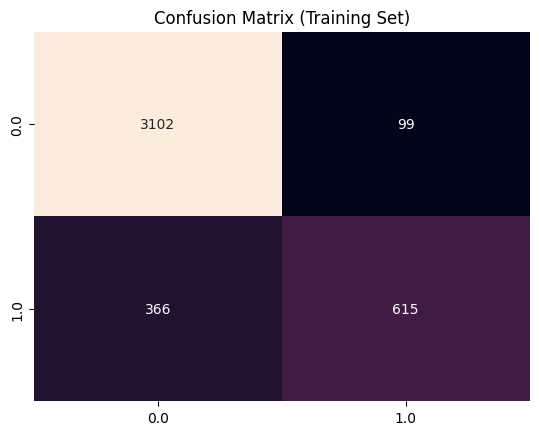

Accuracy on the test set: 74.96%
[[1349  141]
 [ 347  108]]


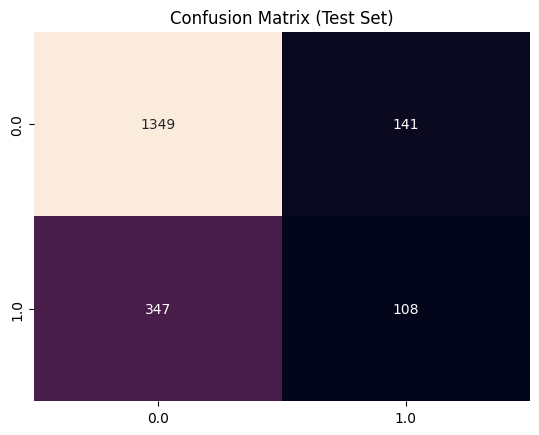

Accuracy on the test set: 74.91%
Training and testing completed.


In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt



# Make predictions on the training set
Y_p_train = cls.predict(X_train)
c_m_train = confusion_matrix(Y_train, Y_p_train)

# Calculate accuracy for the training set
accuracy_train = accuracy_score(Y_train, Y_p_train)
print(c_m_train)
# Visualize the confusion matrix for the training set
sns.heatmap(c_m_train, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Training Set)')
plt.show()

print(f"Accuracy on the test set: {accuracy_test:.2%}")

# Make predictions on the test set
Y_p_test = cls.predict(X_test)
c_m_test = confusion_matrix(Y_test, Y_p_test)

# Calculate accuracy for the test set
accuracy_test = accuracy_score(Y_test, Y_p_test)
print(c_m_test)
# Visualize the confusion matrix for the test set
sns.heatmap(c_m_test, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Test Set)')
plt.show()

print(f"Accuracy on the test set: {accuracy_test:.2%}")
print("Training and testing completed.")


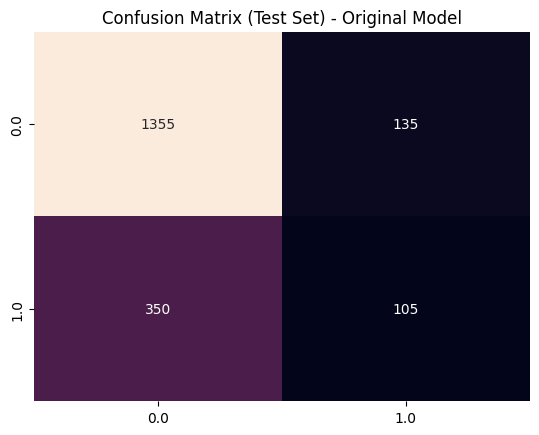

Accuracy on the test set: 75.06%


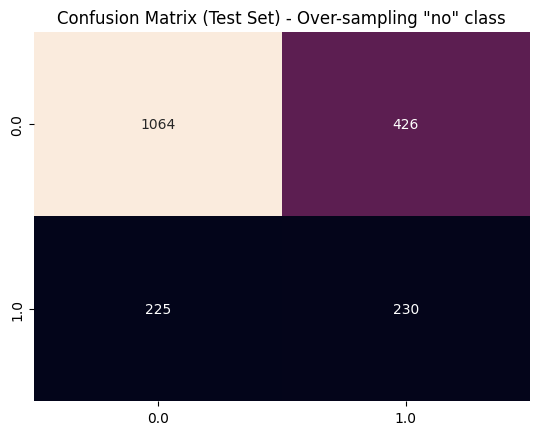

Accuracy on the test set (with over-sampling): 66.53%


In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score
from imblearn.over_sampling import RandomOverSampler
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming X_train, Y_train, X_test, Y_test, and train are defined

# Solution 1: Original model
cls = RandomForestClassifier(
    n_estimators=100,
    criterion='gini',
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    max_leaf_nodes=None,
    bootstrap=True,
    oob_score=True,
    max_samples=0.53
)
cls.fit(X_train, Y_train)

# Make predictions on the test set
Y_p_test = cls.predict(X_test)
c_m_test = confusion_matrix(Y_test, Y_p_test)

# Visualize the confusion matrix for the test set
sns.heatmap(c_m_test, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Test Set) - Original Model')
plt.show()

# Calculate accuracy for the test set
accuracy_test = accuracy_score(Y_test, Y_p_test)
print(f"Accuracy on the test set: {accuracy_test:.2%}")

# Solution 2: Over-sampling the minority class ("no" class)
# Using RandomOverSampler for class 0.0 only
ros = RandomOverSampler(sampling_strategy={1.0: 6000})
X_train_resampled, Y_train_resampled = ros.fit_resample(X_train, Y_train)

cls.fit(X_train_resampled, Y_train_resampled)
Y_p_test = cls.predict(X_test)
c_m_test = confusion_matrix(Y_test, Y_p_test)

sns.heatmap(c_m_test, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Test Set) - Over-sampling "no" class')
plt.show()

# Calculate accuracy for the test set
accuracy_test = accuracy_score(Y_test, Y_p_test)
print(f"Accuracy on the test set (with over-sampling): {accuracy_test:.2%}")



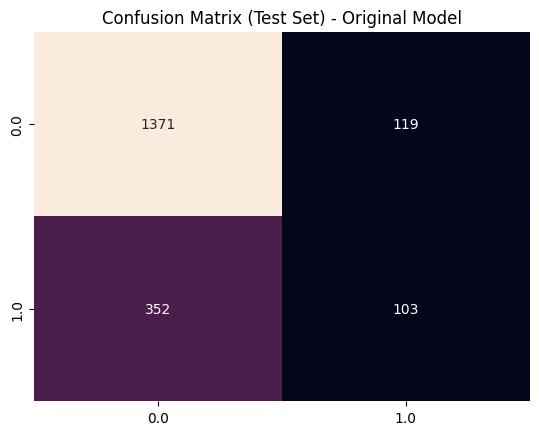

Accuracy on the test set: 75.78%


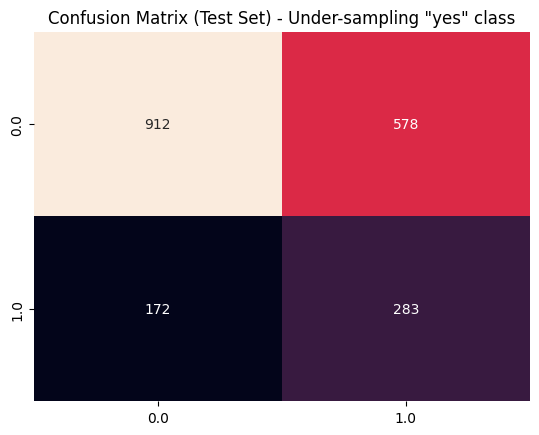

Accuracy on the test set (with under-sampling): 61.44%


In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, accuracy_score
from imblearn.under_sampling import RandomUnderSampler
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming X_train, Y_train, X_test, Y_test, and train are defined

# Solution 1: Original model
cls = RandomForestClassifier(
    n_estimators=100,
    criterion='gini',
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    max_leaf_nodes=None,
    bootstrap=True,
    oob_score=True,
    max_samples=0.53
)
cls.fit(X_train, Y_train)

# Make predictions on the test set
Y_p_test = cls.predict(X_test)
c_m_test = confusion_matrix(Y_test, Y_p_test)

# Visualize the confusion matrix for the test set
sns.heatmap(c_m_test, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Test Set) - Original Model')
plt.show()

# Calculate accuracy for the test set
accuracy_test = accuracy_score(Y_test, Y_p_test)
print(f"Accuracy on the test set: {accuracy_test:.2%}")

# Solution 3: Under-sampling the majority class ("yes" class)
# Using RandomUnderSampler for class 1.0 only
rus = RandomUnderSampler(sampling_strategy={0.0: 1000})
X_train_resampled, Y_train_resampled = rus.fit_resample(X_train, Y_train)

cls.fit(X_train_resampled, Y_train_resampled)
Y_p_test = cls.predict(X_test)
c_m_test = confusion_matrix(Y_test, Y_p_test)

sns.heatmap(c_m_test, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Test Set) - Under-sampling "yes" class')
plt.show()

# Calculate accuracy for the test set
accuracy_test = accuracy_score(Y_test, Y_p_test)
print(f"Accuracy on the test set (with under-sampling): {accuracy_test:.2%}")


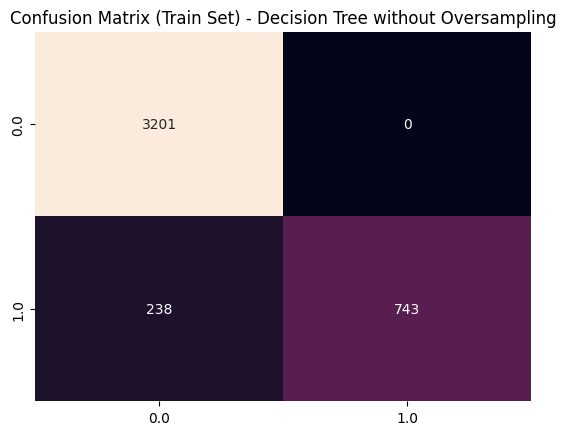

Classification Report:
              precision    recall  f1-score   support

         0.0       0.93      1.00      0.96      3201
         1.0       1.00      0.76      0.86       981

    accuracy                           0.94      4182
   macro avg       0.97      0.88      0.91      4182
weighted avg       0.95      0.94      0.94      4182

Accuracy on the test set: 94.31%

Classification Report (Adjusted Threshold):
              precision    recall  f1-score   support

         0.0       1.00      0.93      0.96      3201
         1.0       0.80      1.00      0.89       981

    accuracy                           0.94      4182
   macro avg       0.90      0.96      0.93      4182
weighted avg       0.95      0.94      0.95      4182

Accuracy on the training set (Adjusted Threshold): 94.31%


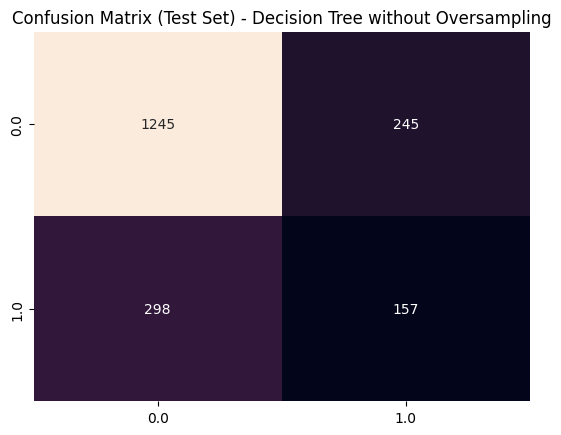

Classification Report:
              precision    recall  f1-score   support

         0.0       0.81      0.84      0.82      1490
         1.0       0.39      0.35      0.37       455

    accuracy                           0.72      1945
   macro avg       0.60      0.59      0.59      1945
weighted avg       0.71      0.72      0.71      1945

Accuracy on the test set: 72.08%

Classification Report (Adjusted Threshold):
              precision    recall  f1-score   support

         0.0       0.81      0.77      0.79      1490
         1.0       0.34      0.39      0.37       455

    accuracy                           0.68      1945
   macro avg       0.58      0.58      0.58      1945
weighted avg       0.70      0.68      0.69      1945

Accuracy on the test set (Adjusted Threshold): 68.38%


In [ ]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

# Assuming you already have X_train, X_test, Y_train, Y_test ready

# Train a DecisionTreeClassifier with 'entropy' criterion on the training data
cls = DecisionTreeClassifier(criterion='entropy', random_state=42)
cls.fit(X_train, Y_train)

# Make predictions on the training set
Y_p_train = cls.predict(X_train)
c_m_train = confusion_matrix(Y_train, Y_p_train)

# Visualize the confusion matrix for the training set
sns.heatmap(c_m_train, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Train Set) - Decision Tree without Oversampling')
plt.show()

# Print classification report for more detailed metrics
print("Classification Report:")
print(classification_report(Y_train, Y_p_train))

# Calculate accuracy for the training set
accuracy_test = accuracy_score(Y_train, Y_p_train)
print(f"Accuracy on the test set: {accuracy_test:.2%}")

# Adjust the decision threshold and evaluate the impact
threshold = 0.0005  # Adjust this threshold as needed
Y_p_train_adjusted = (cls.predict_proba(X_train)[:, 1] > threshold).astype(int)

# Assess the impact on the classification report and accuracy
print("\nClassification Report (Adjusted Threshold):")
print(classification_report(Y_train, Y_p_train_adjusted))

accuracy_train_adjusted = accuracy_score(Y_train, Y_p_train_adjusted)
print(f"Accuracy on the training set (Adjusted Threshold): {accuracy_train_adjusted:.2%}")

# Make predictions on the test set
Y_p_test = cls.predict(X_test)
c_m_test = confusion_matrix(Y_test, Y_p_test)

# Visualize the confusion matrix for the test set
sns.heatmap(c_m_test, annot=True, cbar=False, xticklabels=cls.classes_, yticklabels=cls.classes_, fmt='d')
plt.title('Confusion Matrix (Test Set) - Decision Tree without Oversampling')
plt.show()

# Print classification report for more detailed metrics
print("Classification Report:")
print(classification_report(Y_test, Y_p_test))

# Calculate accuracy for the test set
accuracy_test = accuracy_score(Y_test, Y_p_test)
print(f"Accuracy on the test set: {accuracy_test:.2%}")

# Adjust the decision threshold and evaluate the impact
threshold = 0.5 # Adjust this threshold as needed
Y_p_test_adjusted = (cls.predict_proba(X_test)[:, 1] > threshold).astype(int)

# Assess the impact on the classification report and accuracy
print("\nClassification Report (Adjusted Threshold):")
print(classification_report(Y_test, Y_p_test_adjusted))

accuracy_test_adjusted = accuracy_score(Y_test, Y_p_test_adjusted)
print(f"Accuracy on the test set (Adjusted Threshold): {accuracy_test_adjusted:.2%}")


=== Random Forest ===
--- Évaluation sur le jeu d'entraînement ---
Accuracy (train) : 0.94
F1-score (train) : 0.87
--- Évaluation sur le jeu de test ---
Accuracy (test) : 0.73
F1-score (test) : 0.35
Classification Report (test) :
               precision    recall  f1-score   support

         0.0       0.80      0.87      0.83      1490
         1.0       0.41      0.31      0.35       455

    accuracy                           0.73      1945
   macro avg       0.61      0.59      0.59      1945
weighted avg       0.71      0.73      0.72      1945



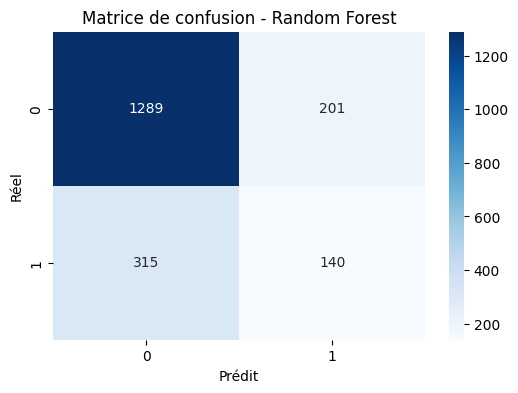

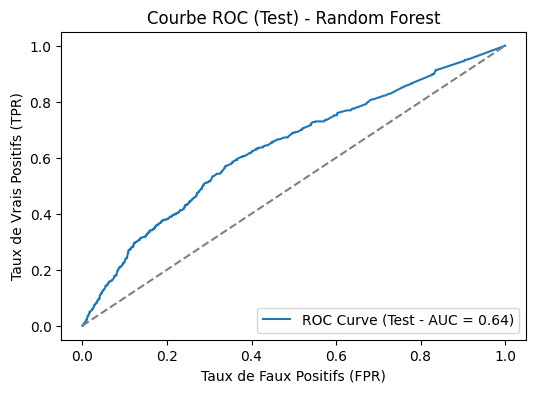

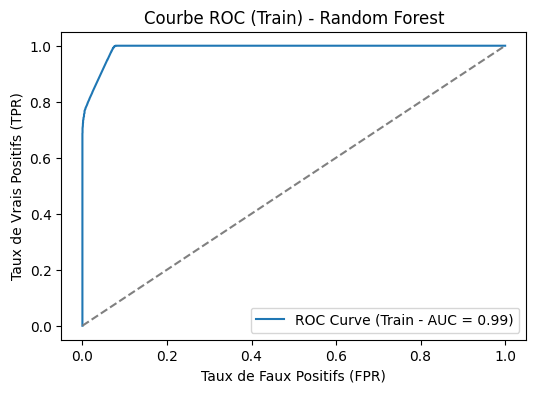

=== Gradient Boosting ===
--- Évaluation sur le jeu d'entraînement ---
Accuracy (train) : 0.79
F1-score (train) : 0.28
--- Évaluation sur le jeu de test ---
Accuracy (test) : 0.77
F1-score (test) : 0.27
Classification Report (test) :
               precision    recall  f1-score   support

         0.0       0.79      0.95      0.86      1490
         1.0       0.52      0.18      0.27       455

    accuracy                           0.77      1945
   macro avg       0.65      0.57      0.57      1945
weighted avg       0.73      0.77      0.72      1945



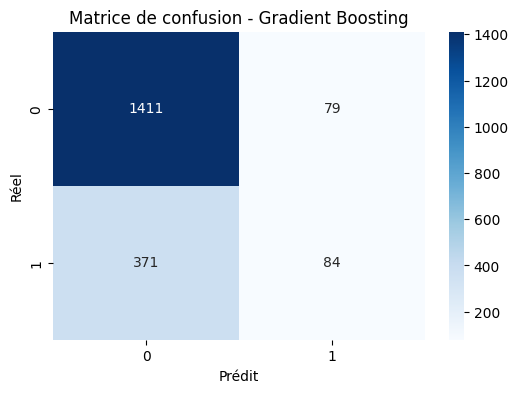

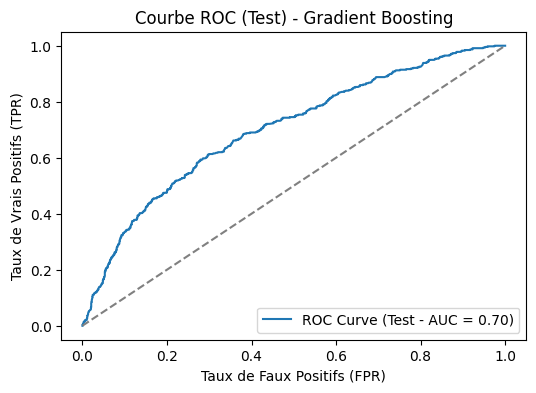

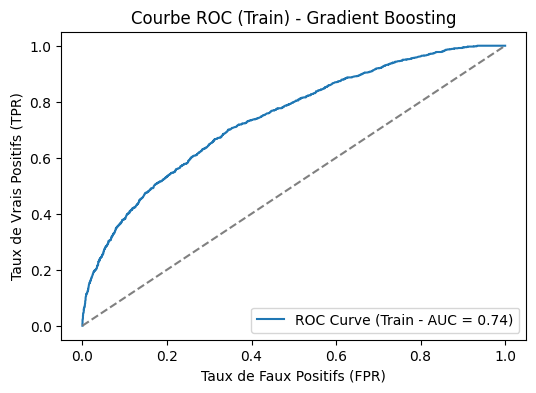

=== Logistic Regression ===
--- Évaluation sur le jeu d'entraînement ---
Accuracy (train) : 0.77
F1-score (train) : 0.18
--- Évaluation sur le jeu de test ---
Accuracy (test) : 0.77
F1-score (test) : 0.18
Classification Report (test) :
               precision    recall  f1-score   support

         0.0       0.78      0.97      0.87      1490
         1.0       0.53      0.11      0.18       455

    accuracy                           0.77      1945
   macro avg       0.65      0.54      0.52      1945
weighted avg       0.72      0.77      0.71      1945



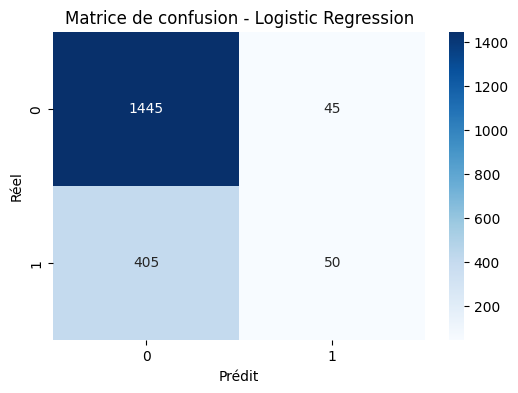

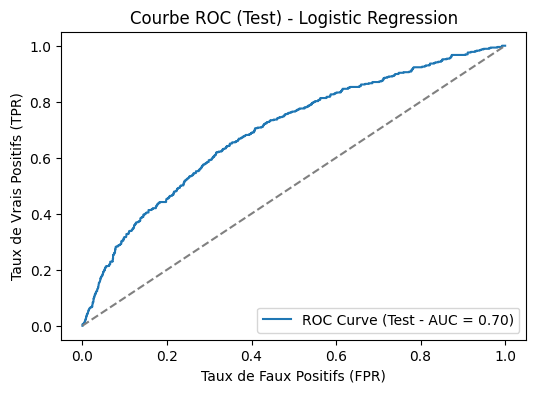

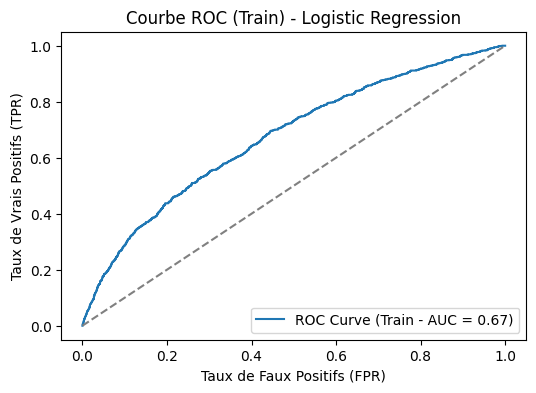

=== SVM ===
--- Évaluation sur le jeu d'entraînement ---
Accuracy (train) : 0.77
F1-score (train) : 0.00
--- Évaluation sur le jeu de test ---
Accuracy (test) : 0.77
F1-score (test) : 0.00
Classification Report (test) :
               precision    recall  f1-score   support

         0.0       0.77      1.00      0.87      1490
         1.0       0.00      0.00      0.00       455

    accuracy                           0.77      1945
   macro avg       0.38      0.50      0.43      1945
weighted avg       0.59      0.77      0.66      1945



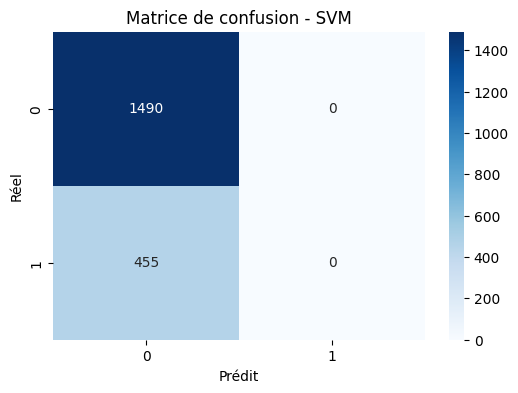

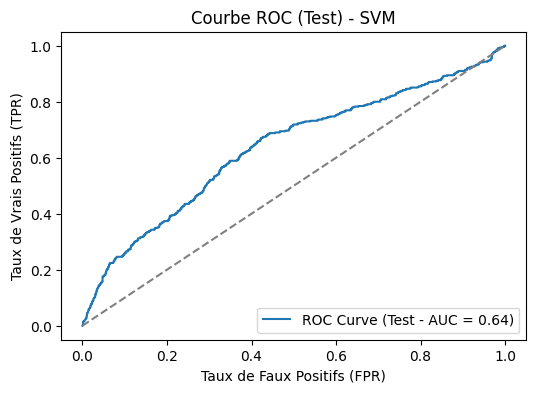

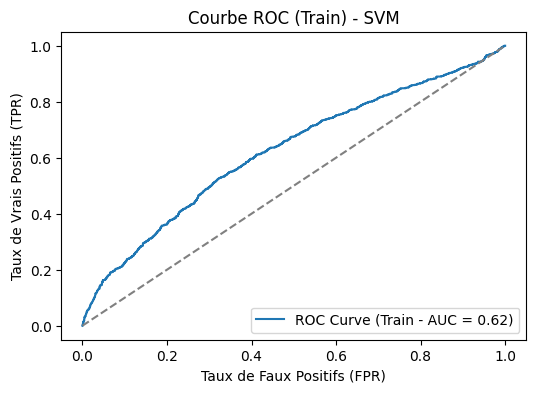

=== KNN ===
--- Évaluation sur le jeu d'entraînement ---
Accuracy (train) : 0.80
F1-score (train) : 0.41
--- Évaluation sur le jeu de test ---
Accuracy (test) : 0.74
F1-score (test) : 0.30
Classification Report (test) :
               precision    recall  f1-score   support

         0.0       0.79      0.89      0.84      1490
         1.0       0.40      0.24      0.30       455

    accuracy                           0.74      1945
   macro avg       0.59      0.56      0.57      1945
weighted avg       0.70      0.74      0.71      1945



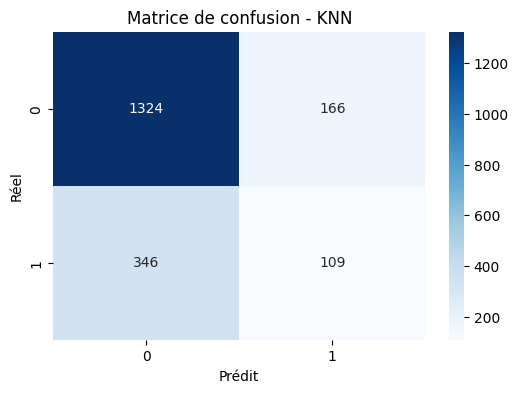

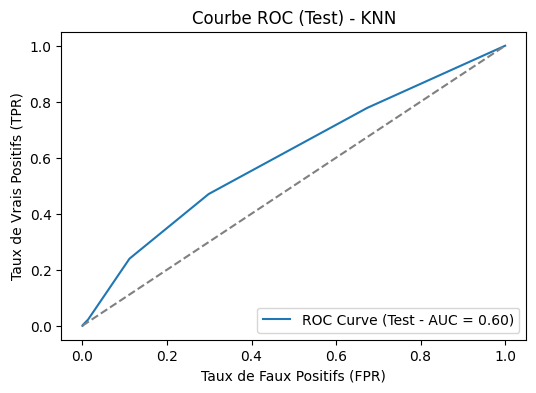

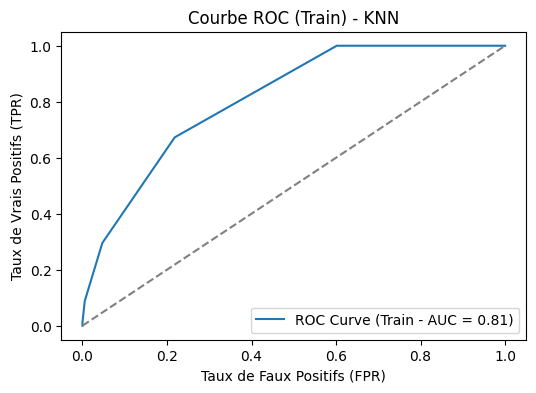

In [ ]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns

# === AJOUT IMPORTANT ===
X = train.drop(columns=["Claim"])
y = train["Claim"]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Liste des modèles
models = {
    "Random Forest": RandomForestClassifier(),
    "Gradient Boosting": GradientBoostingClassifier(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "SVM": SVC(probability=True),
    "KNN": KNeighborsClassifier()
}

# Entraînement et évaluation
for name, model in models.items():
    print(f"=== {name} ===")
    model.fit(X_train, Y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred  = model.predict(X_test)

    y_train_prob = model.predict_proba(X_train)[:, 1] if hasattr(model, "predict_proba") else None
    y_test_prob  = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None

    # Train metrics
    print("\n--- Train ---")
    print("Accuracy :", accuracy_score(Y_train, y_train_pred))
    print("F1-score :", f1_score(Y_train, y_train_pred))

    # Test metrics
    print("\n--- Test ---")
    print("Accuracy :", accuracy_score(Y_test, y_test_pred))
    print("F1-score :", f1_score(Y_test, y_test_pred))
    print(classification_report(Y_test, y_test_pred))

    # Confusion Matrix
    cm = confusion_matrix(Y_test, y_test_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cbar=False)
    plt.title(f"Matrice de confusion - {name}")
    plt.xlabel("Prédit")
    plt.ylabel("Réel")
    plt.show()

    # ROC Curve
    if y_test_prob is not None:
        fpr_test, tpr_test, _ = roc_curve(Y_test, y_test_prob)
        auc_test = roc_auc_score(Y_test, y_test_prob)

        plt.figure(figsize=(5, 4))
        plt.plot(fpr_test, tpr_test, label=f"AUC Test = {auc_test:.2f}")
        plt.plot([0, 1], [0, 1], linestyle='--')
        plt.title(f"ROC Curve - {name}")
        plt.xlabel("FPR")
        plt.ylabel("TPR")
        plt.legend()
        plt.show()


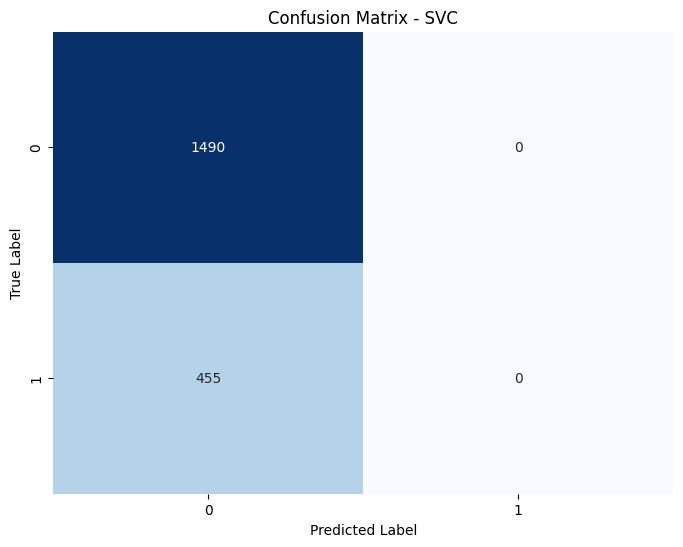

Classification Report - SVC
              precision    recall  f1-score   support

         0.0       0.77      1.00      0.87      1490
         1.0       0.00      0.00      0.00       455

    accuracy                           0.77      1945
   macro avg       0.38      0.50      0.43      1945
weighted avg       0.59      0.77      0.66      1945

Accuracy: 0.7661


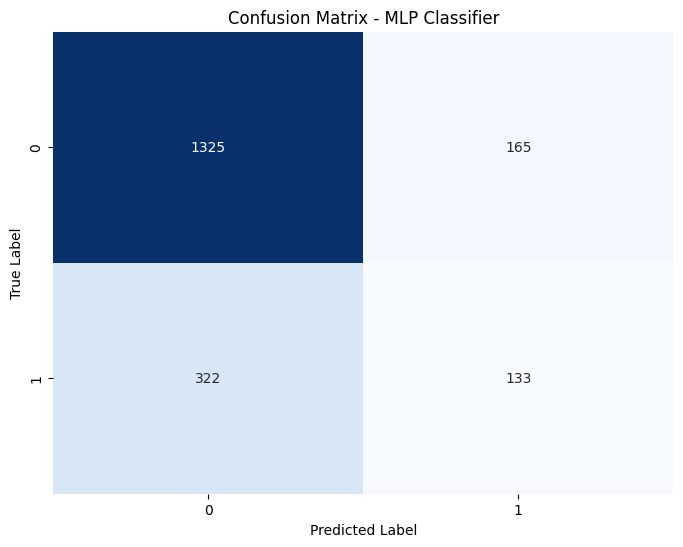

Classification Report - MLP Classifier
              precision    recall  f1-score   support

         0.0       0.80      0.89      0.84      1490
         1.0       0.45      0.29      0.35       455

    accuracy                           0.75      1945
   macro avg       0.63      0.59      0.60      1945
weighted avg       0.72      0.75      0.73      1945

Accuracy: 0.7496


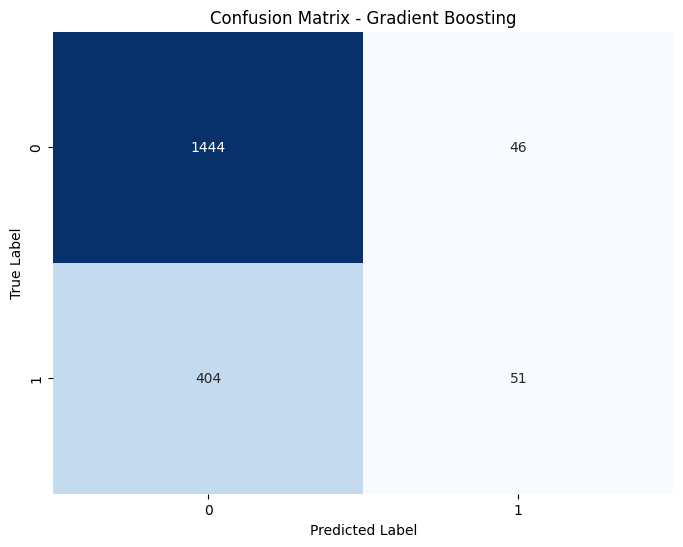

Classification Report - Gradient Boosting
              precision    recall  f1-score   support

         0.0       0.78      0.97      0.87      1490
         1.0       0.53      0.11      0.18       455

    accuracy                           0.77      1945
   macro avg       0.65      0.54      0.52      1945
weighted avg       0.72      0.77      0.71      1945

Accuracy: 0.7686
Best parameters for SVC: {'kernel': 'rbf', 'gamma': 'scale', 'C': 0.1}
Best parameters for MLP: {'learning_rate': 'adaptive', 'hidden_layer_sizes': (50,), 'alpha': 0.0001, 'activation': 'relu'}
Best parameters for Gradient Boosting: {'n_estimators': 100, 'min_samples_split': 2, 'max_depth': 3, 'learning_rate': 0.05}


In [ ]:
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

# === AJOUT IMPORTANT ===
X = train.drop(columns=["Claim"])
y = train["Claim"]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# === Paramètres ===
svc_params = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['rbf', 'poly'],
    'gamma': ['scale', 0.1]
}

mlp_params = {
    'hidden_layer_sizes': [(50,), (100,)],
    'activation': ['relu'],
    'alpha': [0.0001, 0.001],
    'learning_rate': ['adaptive']
}

gb_params = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [3, 4]
}

# === Modèles optimisés ===
svc = RandomizedSearchCV(SVC(random_state=42), svc_params, n_iter=5, cv=5, n_jobs=-1, random_state=42)
svc.fit(X_train, Y_train)

mlp = RandomizedSearchCV(MLPClassifier(random_state=42, max_iter=300), mlp_params, n_iter=5, cv=5, n_jobs=-1, random_state=42)
mlp.fit(X_train, Y_train)

gb = RandomizedSearchCV(GradientBoostingClassifier(random_state=42), gb_params, n_iter=5, cv=5, n_jobs=-1, random_state=42)
gb.fit(X_train, Y_train)

# === Fonction d’évaluation ===
def evaluate_model(model, X_test, Y_test, model_name):
    Y_pred = model.predict(X_test)
    cm = confusion_matrix(Y_test, Y_pred)
    
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cbar=False)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('True Label')
    plt.xlabel('Predicted Label')
    plt.show()
    
    print(f"\nClassification Report - {model_name}")
    print(classification_report(Y_test, Y_pred))
    print(f"Accuracy: {accuracy_score(Y_test, Y_pred):.4f}")

# === Évaluations ===
evaluate_model(svc.best_estimator_, X_test, Y_test, "SVC")
evaluate_model(mlp.best_estimator_, X_test, Y_test, "MLP Classifier")
evaluate_model(gb.best_estimator_, X_test, Y_test, "Gradient Boosting")

# === Meilleurs paramètres ===
print("Best parameters for SVC:", svc.best_params_)
print("Best parameters for MLP:", mlp.best_params_)
print("Best parameters for Gradient Boosting:", gb.best_params_)


<Figure size 1200x600 with 0 Axes>

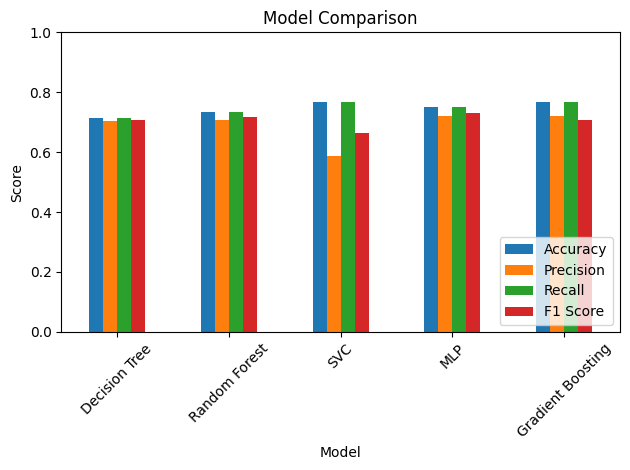

               Model  Accuracy  Precision    Recall  F1 Score
0      Decision Tree  0.713625   0.704160  0.713625  0.708560
1      Random Forest  0.735219   0.708308  0.735219  0.718213
2                SVC  0.766067   0.586858  0.766067  0.664594
3                MLP  0.749614   0.720702  0.749614  0.729777
4  Gradient Boosting  0.768638   0.721589  0.768638  0.706019


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split

# === 1. Créer X et y ===
X = train.drop(columns=["Claim"])
y = train["Claim"]

# === 2. Créer X_train, X_test, Y_train, Y_test ===
X_train, X_test, Y_train, Y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# === 3. Définir les modèles avec leur nom ===
models = [
    ("Random Forest", RandomForestClassifier(class_weight='balanced', random_state=42)),
    ("Logistic Regression", LogisticRegression(class_weight='balanced', max_iter=1000))
]

# === 4. Évaluer les modèles ===
results = []

for name, model in models:
    model.fit(X_train, Y_train)
    y_pred = model.predict(X_test)
    
    accuracy = accuracy_score(Y_test, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        Y_test, y_pred, average='weighted'
    )
    
    results.append((name, accuracy, precision, recall, f1))

# === 5. Résultats en DataFrame ===
df_results = pd.DataFrame(
    results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score']
)

# === 6. Visualisation ===
plt.figure(figsize=(12, 6))
df_results.set_index('Model').plot(kind='bar', ylim=[0, 1])
plt.title('Model Comparison')
plt.ylabel('Score')
plt.xticks(rotation=45)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

print(df_results)
